# Avance 1 – Limpieza y exploración (Chicago)
En esta sección cargo la base de 30.000 clientes, corrijo los errores sobre la base completa, filtro Chicago (la ciudad con más clientes) y hago las tablas y gráficos iniciales.



In [2]:
%pip install pandas numpy seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# ============================================================
# BLOQUE 1: CARGA DE DATOS
# ============================================================

# Importamos las librerías que vamos a usar
import pandas as pd    # pandas sirve para trabajar con tablas
import numpy as np     # numpy lo usamos para marcar datos vacíos (np.nan)

# Le decimos a pandas que muestre todas las columnas y no las corte con "..."
pd.set_option("display.max_columns", None)

# Leemos el archivo CSV y lo guardamos en df_raw (raw = datos crudos, sin tocar)
df_raw = pd.read_csv("base_datos_restaurantes_USA_v2.csv")

# Vemos cuántas filas (clientes) y columnas (variables) tiene la base
print("Filas:", df_raw.shape[0], "| Columnas:", df_raw.shape[1])

# Mostramos las primeras 5 filas para ver cómo se ven los datos
# display() muestra la tabla con formato bonito (viene incluido en Jupyter)
display(df_raw.head())

# Vemos el nombre de cada columna, su tipo de dato y cuántos valores llenos tiene
df_raw.info()

# Resumen de las columnas numéricas: promedio, mínimo, máximo, etc.
# Aquí ya se ven valores raros: edad mínima -5, edad máxima 300 y frecuencia mínima -3
display(df_raw.describe().round(1))

Filas: 30000 | Columnas: 17


,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,881-476-1426,NaN,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,NaN,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,NaN,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   nombre                     30000 non-null  str    
 2   apellido                   30000 non-null  str    
 3   edad                       29899 non-null  float64
 4   genero                     30000 non-null  str    
 5   ciudad_residencia          30000 non-null  str    
 6   estrato_socioeconomico     30000 non-null  str    
 7   frecuencia_visita          30000 non-null  int64  
 8   promedio_gasto_comida      29855 non-null  float64
 9   ocio                       30000 non-null  str    
 10  consume_licor              30000 non-null  str    
 11  preferencias_alimenticias  28597 non-null  str    
 12  membresia_premium          30000 non-null  str    
 13  telefono_contacto          14834 non-null  str    
 14  c

,id_persona,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,3.000000e+04,29899.0,30000.0,29855.0,30000.0
mean,5.504765e+09,49.7,3.9,32.6,5389.8
std,2.602799e+09,23.8,2.7,26.4,4538.5
min,1.000153e+09,-5.0,-3.0,0.0,800.0
25%,3.243617e+09,33.0,2.0,13.3,1860.0
50%,5.515865e+09,49.0,4.0,25.5,3402.0
75%,7.754426e+09,65.0,5.0,44.4,7761.0
max,9.999627e+09,300.0,10.0,150.0,17999.0


In [2]:
# ============================================================
# BLOQUE 2: LIMPIEZA DE DATOS
# ============================================================

# --- Paso 1: Identificar los problemas en la base completa ---

# Tabla de datos vacíos (nulos): cuántos hay por columna y qué porcentaje representan
nulos = df_raw.isnull().sum().to_frame("nulos")
nulos["porcentaje"] = (nulos["nulos"] / len(df_raw) * 100).round(1)
display(nulos[nulos["nulos"] > 0])     # mostramos solo las columnas que tienen nulos

# Contamos filas repetidas exactamente iguales
print("Filas duplicadas:", df_raw.duplicated().sum())

# Contamos si algún cliente (id_persona) aparece más de una vez
print("IDs repetidos:", df_raw["id_persona"].duplicated().sum())

# Buscamos edades que no tienen sentido: menores de 18 o mayores de 100
edades_raras = df_raw[(df_raw["edad"] < 18) | (df_raw["edad"] > 100)]
print("Edades raras:", len(edades_raras), "| Valores:", edades_raras["edad"].unique())

# Contamos frecuencias de visita negativas (nadie visita un restaurante -3 veces)
print("Frecuencias negativas:", (df_raw["frecuencia_visita"] < 0).sum())


# --- Paso 2: Corregir los errores en la base completa ---

# Limpiamos la base completa UNA sola vez: así la usamos limpia aquí (Chicago) y en el Avance 3 (todas las ciudades)
df_total = df_raw.copy()   # .copy() protege la tabla original

# Edades menores de 18 o mayores de 100 -> las dejamos vacías (np.nan)
# POR QUÉ: un -5 o un 300 no dice cuál es la edad real; rellenarlos sería inventar un dato
df_total.loc[(df_total["edad"] < 18) | (df_total["edad"] > 100), "edad"] = np.nan

# Frecuencias negativas -> las dejamos vacías
# POR QUÉ: esos clientes sí tienen gasto, o sea sí visitan, pero no sabemos cuántas veces
df_total.loc[df_total["frecuencia_visita"] < 0, "frecuencia_visita"] = np.nan

# Preferencias alimenticias vacías -> "No especificado"
# POR QUÉ: así esos clientes aparecen en las tablas como un grupo propio y no se pierden
df_total["preferencias_alimenticias"] = df_total["preferencias_alimenticias"].fillna("No especificado")

# El id lo pasamos a texto
# POR QUÉ: es un código para identificar al cliente, no un número para sumar o promediar
df_total["id_persona"] = df_total["id_persona"].astype(str)

# Duplicados: no hay, así que no hay que eliminar nada
# Teléfono y correo: tienen ~50% vacíos, pero no los usamos en el análisis, así que se dejan igual


# --- Paso 3: Filtrar por una ciudad ---

# Vemos cuántos clientes hay en cada ciudad para elegir cuál analizar
display(df_total["ciudad_residencia"].value_counts().to_frame("clientes"))

# CRITERIO: elegimos Chicago porque es la ciudad con más clientes,
# así el análisis se basa en la muestra más grande posible
df = df_total[df_total["ciudad_residencia"] == "Chicago"].copy()
print("Clientes en Chicago:", len(df))


# --- Paso 4: Verificar que la limpieza quedó bien ---

# Volvemos a hacer la tabla de nulos, ahora con la base de Chicago ya limpia
nulos_final = df.isnull().sum().to_frame("nulos")
nulos_final["porcentaje"] = (nulos_final["nulos"] / len(df) * 100).round(1)
display(nulos_final[nulos_final["nulos"] > 0])

# Confirmamos que ya no hay edades raras ni frecuencias negativas
print("Edad mínima:", df["edad"].min(), "| Edad máxima:", df["edad"].max())
print("Frecuencia mínima:", df["frecuencia_visita"].min())

,nulos,porcentaje
edad,101,0.3
promedio_gasto_comida,145,0.5
preferencias_alimenticias,1403,4.7
telefono_contacto,15166,50.6
correo_electronico,15072,50.2


Filas duplicadas: 0
IDs repetidos: 0
Edades raras: 207 | Valores: [300.  -5.]
Frecuencias negativas: 1547


,clientes
ciudad_residencia,
Chicago,5384
NYC,4769
Miami,3186
San Diego,3075
Dallas,2602
Boston,2547
Denver,2523
Houston,2212
Seattle,2191


Clientes en Chicago: 5384


,nulos,porcentaje
edad,52,1.0
frecuencia_visita,286,5.3
promedio_gasto_comida,35,0.7
telefono_contacto,2730,50.7
correo_electronico,2712,50.4


Edad mínima: 18.0 | Edad máxima: 80.0
Frecuencia mínima: 0.0


==== genero ====


,clientes,porcentaje
genero,,
Masculino,2716,50.4
Femenino,2668,49.6


==== estrato_socioeconomico ====


,clientes,porcentaje
estrato_socioeconomico,,
Medio,1798,33.4
Alto,1511,28.1
Bajo,1148,21.3
Muy Alto,927,17.2


==== preferencias_alimenticias ====


,clientes,porcentaje
preferencias_alimenticias,,
Carnes,1589,29.5
Vegetariano,1123,20.9
Mariscos,696,12.9
Otro,591,11.0
Vegano,571,10.6
Pescado,546,10.1
No especificado,268,5.0


... (14 outputs left out)

==== Gasto promedio por comida según estrato (USD, solo quienes comen afuera) ====


,gasto_promedio_usd
estrato_socioeconomico,
Bajo,7.5
Medio,17.5
Alto,32.5
Muy Alto,54.2


Archivo guardado: clientes_chicago_limpio.csv


<Axes: title={'center': 'Gasto promedio por comida según estrato (Chicago, USD)'}, ylabel='USD'>

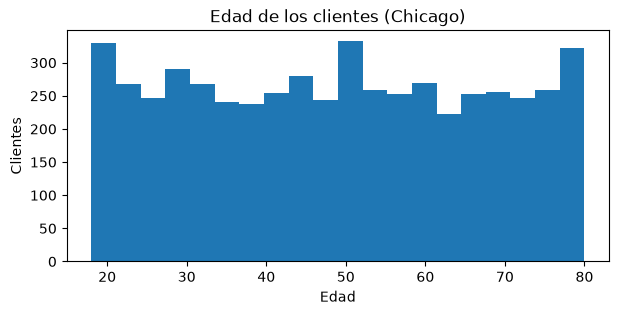

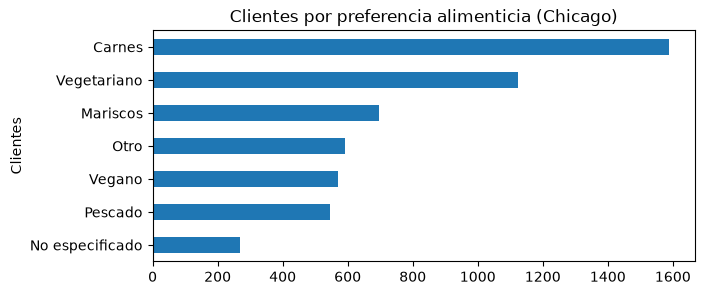

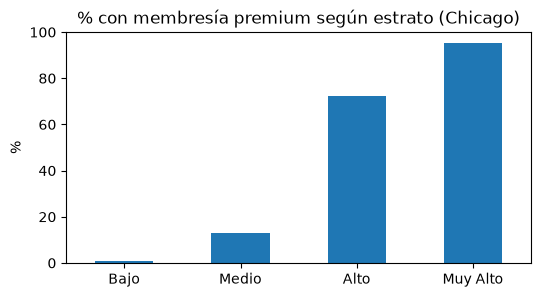

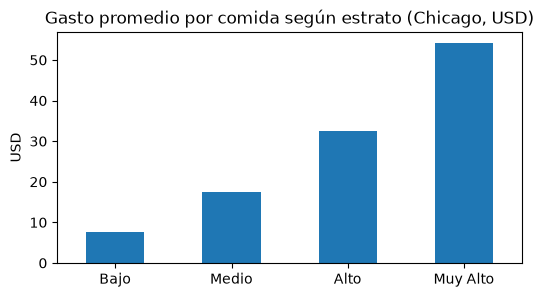

In [3]:
# ============================================================
# BLOQUE 3: TABULACIÓN
# ============================================================

# Orden lógico del estrato (si no, pandas lo ordena alfabéticamente: Alto, Bajo, Medio...)
orden_estrato = ["Bajo", "Medio", "Alto", "Muy Alto"]


# --- Paso 1: Tabla de cada variable ---

# Lista de las columnas que queremos analizar
columnas = ["genero", "estrato_socioeconomico", "preferencias_alimenticias",
            "consume_licor", "ocio", "membresia_premium", "tipo_de_pago_mas_usado"]

# Para cada columna de la lista hacemos una tabla
for columna in columnas:
    # Contamos cuántos clientes hay en cada categoría
    tabla = df[columna].value_counts().to_frame("clientes")
    # Agregamos una columna con el porcentaje que representa cada categoría
    tabla["porcentaje"] = (tabla["clientes"] / len(df) * 100).round(1)
    print("====", columna, "====")
    display(tabla)


# --- Paso 2: Tablas cruzadas en porcentaje ---

# ¿Qué % de hombres y de mujeres consume licor? (cada fila suma 100%)
licor_genero = (pd.crosstab(df["genero"], df["consume_licor"], normalize="index") * 100).round(1)
print("==== % que consume licor según género ====")
display(licor_genero)

# ¿Qué comida prefieren hombres y mujeres? (cada columna suma 100%)
comida_genero = (pd.crosstab(df["preferencias_alimenticias"], df["genero"], normalize="columns") * 100).round(1)
print("==== % de cada preferencia alimenticia según género ====")
display(comida_genero)

# ¿Qué % de cada estrato tiene membresía premium? (cada fila suma 100%)
premium_estrato = (pd.crosstab(df["estrato_socioeconomico"], df["membresia_premium"], normalize="index") * 100).round(1)
premium_estrato = premium_estrato.reindex(orden_estrato)   # ordenamos de Bajo a Muy Alto
print("==== % con membresía premium según estrato ====")
display(premium_estrato)


# --- Paso 3: Gasto promedio por comida según estrato ---

# Solo clientes que sí comen afuera
# POR QUÉ: los clientes con 0 visitas tienen gasto 0, y si los dejamos bajan el promedio "por comida"
comen_afuera = df[df["promedio_gasto_comida"] > 0]

# Agrupamos por estrato y calculamos cuánto gasta en promedio cada grupo por comida
gasto_estrato = (comen_afuera.groupby("estrato_socioeconomico")["promedio_gasto_comida"]
                 .mean().round(1).reindex(orden_estrato).to_frame("gasto_promedio_usd"))
print("==== Gasto promedio por comida según estrato (USD, solo quienes comen afuera) ====")
display(gasto_estrato)


# --- Paso 4: Guardar la base limpia para el siguiente avance ---
df.to_csv("clientes_chicago_limpio.csv", index=False)   # index=False evita una columna extra
print("Archivo guardado: clientes_chicago_limpio.csv")


# --- Paso 5: Gráficos iniciales (con el .plot() que trae pandas) ---
# Usamos doble corchete [[ ]] para que cada gráfico salga en su propia figura;
# con un solo corchete, varios gráficos en la misma celda se dibujan uno encima del otro

# Distribución de edades después de la limpieza
df[["edad"]].plot(kind="hist", bins=20, legend=False, figsize=(7, 3),
                  title="Edad de los clientes (Chicago)", xlabel="Edad", ylabel="Clientes")

# Cuántos clientes tiene cada preferencia alimenticia
df["preferencias_alimenticias"].value_counts().sort_values().to_frame("clientes").plot(
    kind="barh", legend=False, figsize=(7, 3), title="Clientes por preferencia alimenticia (Chicago)",
    xlabel="", ylabel="Clientes")

# % con membresía premium en cada estrato (usamos la tabla del Paso 2)
premium_estrato[["Sí"]].plot(kind="bar", legend=False, rot=0, figsize=(6, 3),
                             title="% con membresía premium según estrato (Chicago)", xlabel="", ylabel="%")

# Gasto promedio por comida según estrato (usamos la tabla del Paso 3)
gasto_estrato.plot(kind="bar", legend=False, rot=0, figsize=(6, 3),
                   title="Gasto promedio por comida según estrato (Chicago, USD)", xlabel="", ylabel="USD")

## Hallazgos – Avance 1 (Chicago, 5.384 clientes)
- **Limpieza:** en la base completa había 207 edades imposibles (−5 y 300), 1.547 frecuencias negativas, 1.403 preferencias vacías y ningún duplicado. En Chicago quedan vacías 52 edades, 286 frecuencias y 35 gastos por comida.
- **Género:** casi mitad y mitad (50,4% masculino, 49,6% femenino). La edad se reparte de forma pareja entre 18 y 80 años.
- **Estrato:** Medio (33,4%) y Alto (28,1%) son los más comunes; Muy Alto es el 17,2%.
- **Comida:** Carnes (29,5%) y Vegetariano (20,9%) son las preferencias principales. Hombres y mujeres prefieren casi lo mismo.
- **Licor:** lo consume el 62,7% (64,5% de las mujeres y 60,9% de los hombres).
- **Membresía:** la tiene el 41,1%, y depende del estrato: 0,7% en Bajo y 95,3% en Muy Alto.
- **Gasto por comida:** sube con el estrato, de 7,5 USD en Bajo a 54,2 USD en Muy Alto.
- **Pago:** efectivo 39,4%, tarjeta 33,2%, app 25,5% y criptomoneda 1,8%.

# Avance 3 – Análisis y visualizaciones
En esta sección uso la base completa (todas las ciudades) para responder preguntas clave
del negocio con gráficos: distribución de clientes, gasto, preferencias, membresías y consumo de alcohol.

Clientes en la base completa: 30000
Clientes con gasto mensual calculado: 28318


count    28318.0
mean       175.6
std        209.2
min          0.0
25%         39.4
50%        102.4
75%        227.6
max       1499.7
Name: gasto_mensual, dtype: float64

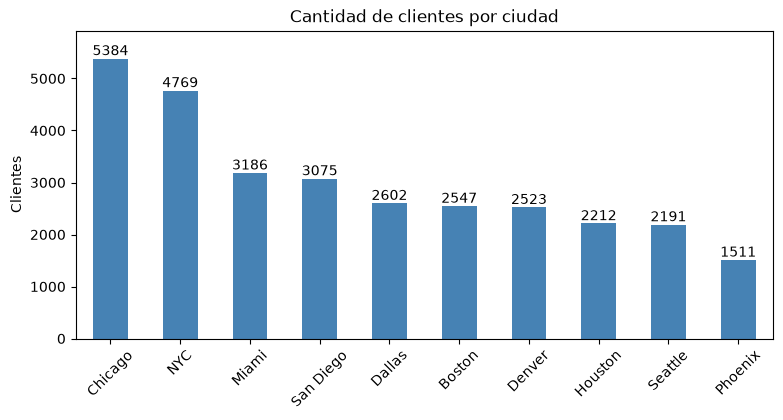

==== Clientes por estrato socioeconómico (todas las ciudades) ====


,clientes,porcentaje
estrato_socioeconomico,,
Bajo,6161,20.5
Medio,9325,31.1
Alto,9038,30.1
Muy Alto,5476,18.3


In [4]:
# ============================================================
# BLOQUE 4 (AVANCE 3): PREPARACIÓN, DIAGRAMACIÓN Y LISTADO
# ============================================================

# Importamos matplotlib para hacer gráficos
import matplotlib.pyplot as plt


# --- Paso 1: Preparar la base completa ---

# Las preguntas de este avance son sobre TODAS las ciudades, no solo Chicago:
# usamos df_total, la base completa que ya limpiamos en el Bloque 2

# Creamos el gasto mensual: visitas al mes x gasto por comida
# SUPUESTO: frecuencia_visita son visitas al mes (la base no lo dice, pero la consigna habla de gasto mensual)
# Los clientes sin frecuencia o sin gasto quedan sin gasto mensual (vacío)
df_total["gasto_mensual"] = df_total["frecuencia_visita"] * df_total["promedio_gasto_comida"]

# Revisamos cómo quedó
print("Clientes en la base completa:", len(df_total))
print("Clientes con gasto mensual calculado:", df_total["gasto_mensual"].notna().sum())
display(df_total["gasto_mensual"].describe().round(1))   # resumen del gasto mensual


# --- Paso 2: Diagrama de barras con la cantidad de clientes por ciudad ---

# Contamos cuántos clientes hay en cada ciudad (ya viene ordenado de mayor a menor)
clientes_ciudad = df_total["ciudad_residencia"].value_counts()

ax = clientes_ciudad.plot(kind="bar", color="steelblue", figsize=(9, 4))   # gráfico de barras
ax.bar_label(ax.containers[0])          # escribe el número encima de cada barra
ax.margins(y=0.1)                       # deja espacio arriba para que el número no se corte
plt.title("Cantidad de clientes por ciudad")
plt.xlabel("")
plt.ylabel("Clientes")
plt.xticks(rotation=45)                 # inclina los nombres de las ciudades para que no se monten
plt.show()


# --- Paso 3: Listado de clientes por estrato socioeconómico ---

# Contamos clientes por estrato y los ordenamos de Bajo a Muy Alto
listado_estrato = df_total["estrato_socioeconomico"].value_counts().reindex(orden_estrato).to_frame("clientes")
listado_estrato["porcentaje"] = (listado_estrato["clientes"] / len(df_total) * 100).round(1)
print("==== Clientes por estrato socioeconómico (todas las ciudades) ====")
display(listado_estrato)

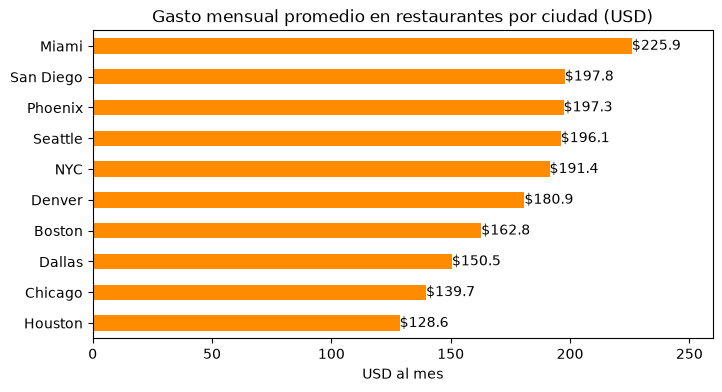

==== Gasto mensual promedio por ciudad y estrato (USD) ====


estrato_socioeconomico,Bajo,Medio,Alto,Muy Alto
ciudad_residencia,,,,
Boston,15.0,69.0,174.0,427.0
Chicago,11.0,63.0,163.0,410.0
Dallas,15.0,79.0,160.0,520.0
Denver,15.0,89.0,206.0,505.0
Houston,18.0,89.0,143.0,379.0
Miami,27.0,88.0,201.0,508.0
NYC,21.0,106.0,232.0,601.0
Phoenix,20.0,97.0,226.0,569.0
San Diego,19.0,78.0,189.0,472.0


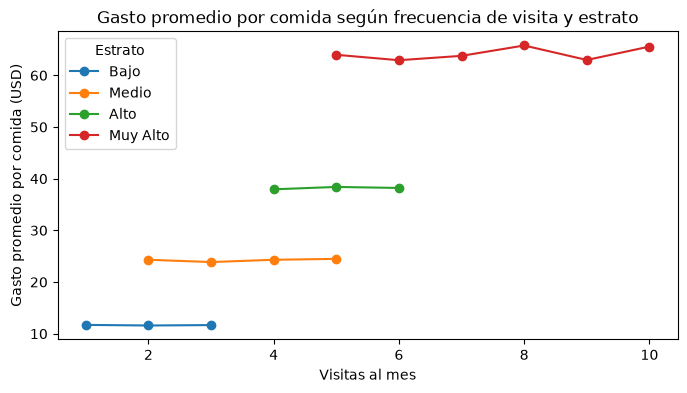

,frecuencia_visita,promedio_gasto_comida
estrato_socioeconomico,,
Bajo,2.0,11.7
Medio,3.5,24.2
Alto,5.0,38.1
Muy Alto,7.5,64.4


% del estrato Bajo que nunca visita restaurantes: 23.7


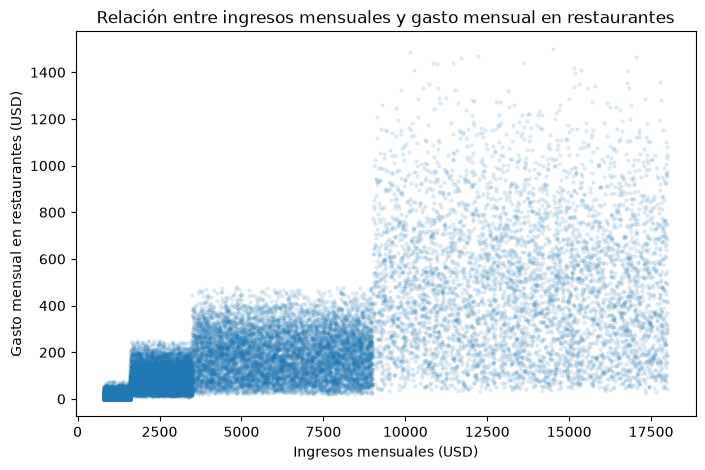

Correlación entre ingresos y gasto mensual: 0.71
Correlación en estrato Bajo : 0.01
Correlación en estrato Medio : -0.0
Correlación en estrato Alto : 0.0
Correlación en estrato Muy Alto : -0.02


,min,max
estrato_socioeconomico,,
Bajo,800,1599
Medio,1600,3499
Alto,3500,8999
Muy Alto,9002,17999


In [5]:
# ============================================================
# BLOQUE 5 (AVANCE 3): GRÁFICOS DE GASTO
# ============================================================

# --- Gráfico 1: ciudades donde más se gasta en promedio al mes ---

# Agrupamos por ciudad y calculamos el gasto mensual promedio, ordenado de menor a mayor
gasto_ciudad = df_total.groupby("ciudad_residencia")["gasto_mensual"].mean().round(1).sort_values()

ax = gasto_ciudad.plot(kind="barh", color="darkorange", figsize=(8, 4))   # barras horizontales
ax.bar_label(ax.containers[0], fmt="$%.1f")    # escribe el valor en dólares al lado de cada barra
ax.margins(x=0.15)
plt.title("Gasto mensual promedio en restaurantes por ciudad (USD)")
plt.xlabel("USD al mes")
plt.ylabel("")
plt.show()

# Gasto mensual por ciudad DENTRO de cada estrato
# POR QUÉ: las ciudades tienen distinta mezcla de estratos; así comparamos clientes parecidos entre ciudades
print("==== Gasto mensual promedio por ciudad y estrato (USD) ====")
display(df_total.pivot_table(index="ciudad_residencia", columns="estrato_socioeconomico",
                             values="gasto_mensual", aggfunc="mean")[orden_estrato].round(0))


# --- Gráfico 2: frecuencia de visita vs gasto por comida, según estrato ---

# Solo clientes que sí comen afuera
# POR QUÉ: los clientes con 0 visitas tienen gasto 0, y si los dejamos bajan el promedio "por comida"
comen_afuera_total = df_total[df_total["promedio_gasto_comida"] > 0]

# Tabla: filas = visitas al mes, columnas = estrato, valores = gasto promedio por comida
frecuencia_gasto = comen_afuera_total.pivot_table(index="frecuencia_visita", columns="estrato_socioeconomico",
                                                  values="promedio_gasto_comida", aggfunc="mean")[orden_estrato]

# Gráfico de líneas: una línea por estrato
frecuencia_gasto.plot(marker="o", figsize=(8, 4))
plt.title("Gasto promedio por comida según frecuencia de visita y estrato")
plt.xlabel("Visitas al mes")
plt.ylabel("Gasto promedio por comida (USD)")
plt.legend(title="Estrato")
plt.show()

# Tabla resumen: visitas y gasto por comida promedio de cada estrato (solo quienes comen afuera)
display(comen_afuera_total.groupby("estrato_socioeconomico")[["frecuencia_visita", "promedio_gasto_comida"]]
        .mean().reindex(orden_estrato).round(1))

# ¿Qué % del estrato Bajo nunca visita restaurantes? (solo Bajo tiene clientes con 0 visitas)
bajo = df_total[df_total["estrato_socioeconomico"] == "Bajo"]
# (bajo["frecuencia_visita"] == 0) da Verdadero/Falso por cliente; el promedio de eso es la proporción de Verdaderos
pct_nunca_visita = (bajo["frecuencia_visita"] == 0).mean() * 100
print("% del estrato Bajo que nunca visita restaurantes:", round(pct_nunca_visita, 1))


# --- Gráfico 3: dispersión entre ingresos mensuales y gasto mensual ---

plt.figure(figsize=(8, 5))
# Cada punto es un cliente; alpha hace los puntos transparentes para ver dónde se amontonan
plt.scatter(df_total["ingresos_mensuales"], df_total["gasto_mensual"], alpha=0.1, s=5)
plt.title("Relación entre ingresos mensuales y gasto mensual en restaurantes")
plt.xlabel("Ingresos mensuales (USD)")
plt.ylabel("Gasto mensual en restaurantes (USD)")
plt.show()

# La correlación mide qué tan relacionadas están dos variables: va de -1 a 1
# Cerca de 1 = cuando una sube, la otra también sube
print("Correlación entre ingresos y gasto mensual:",
      df_total["ingresos_mensuales"].corr(df_total["gasto_mensual"]).round(2))


# Correlación DENTRO de cada estrato: comparamos solo personas del mismo estrato
# POR QUÉ: el gráfico muestra "escalones"; queremos saber si dentro de cada escalón también hay relación
for estrato in orden_estrato:
    grupo = df_total[df_total["estrato_socioeconomico"] == estrato]    # solo clientes de ese estrato
    print("Correlación en estrato", estrato, ":", grupo["ingresos_mensuales"].corr(grupo["gasto_mensual"]).round(2))

# Rango de ingresos de cada estrato
# POR QUÉ: explica los "escalones": cada estrato es un tramo de ingresos que no se cruza con los otros
display(df_total.groupby("estrato_socioeconomico")["ingresos_mensuales"].agg(["min", "max"]).reindex(orden_estrato))

preferencias_alimenticias,Carnes,Mariscos,No especificado,Otro,Pescado,Vegano,Vegetariano
ciudad_residencia,,,,,,,
Boston,21.0,19.4,4.0,7.8,10.7,9.4,27.8
Chicago,29.5,12.9,5.0,11.0,10.1,10.6,20.9
Dallas,31.6,14.1,5.0,9.6,9.2,9.9,20.7
Denver,25.0,18.5,4.7,6.8,9.9,10.2,24.8
Houston,32.4,15.1,4.0,10.8,10.4,8.9,18.6
Miami,16.0,25.7,4.6,9.2,9.6,12.0,22.8
NYC,31.7,16.8,4.2,8.3,9.1,12.3,17.6
Phoenix,27.5,13.8,5.0,10.2,13.2,10.3,19.9
San Diego,21.3,19.0,6.2,6.3,9.4,13.2,24.6


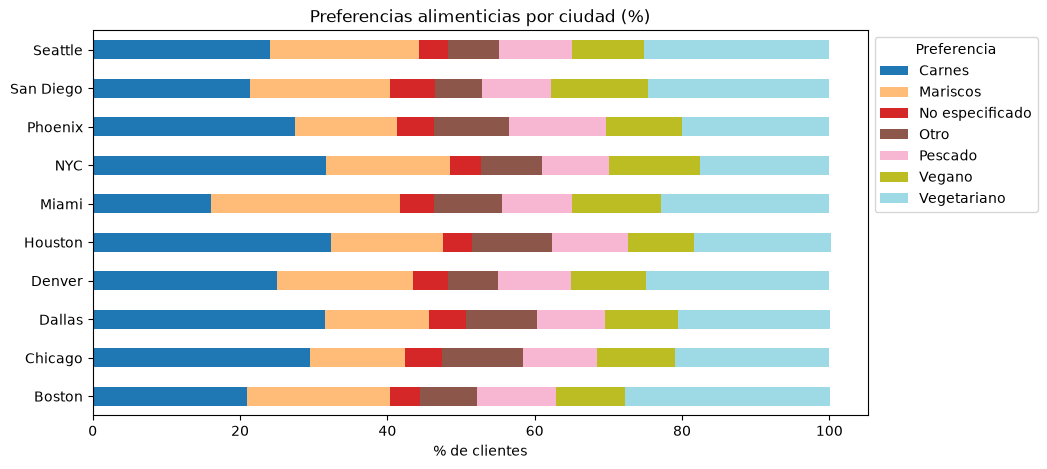

Gasto mensual mínimo para estar en el top 10%: 422.9 USD
==== Gasto mensual: top 10% vs resto ====


,count,mean,median
grupo_gasto,,,
Resto,25486,118.2,86.6
Top 10%,2832,692.1,642.3


grupo_gasto,Resto,Top 10%
preferencias_alimenticias,,
Carnes,26.5,25.5
Vegetariano,21.9,23.7
Mariscos,17.3,17.8
Vegano,10.8,11.3
Pescado,10.0,9.7
Otro,8.9,7.5
No especificado,4.6,4.7


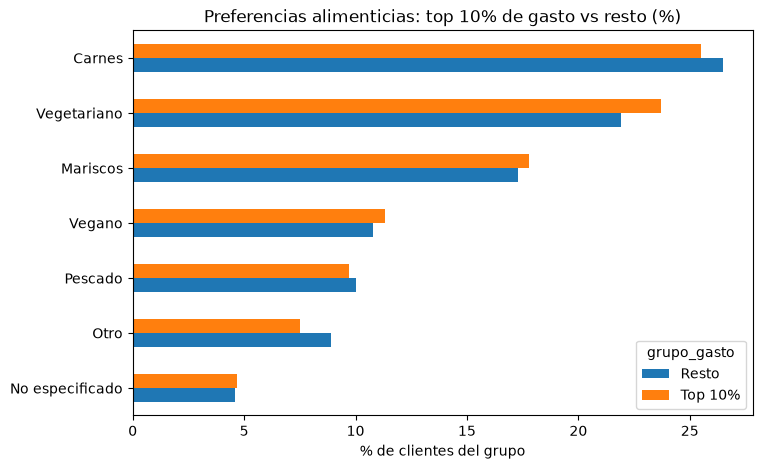

==== Estrato: top 10% vs resto ====


grupo_gasto,Resto,Top 10%
estrato_socioeconomico,,
Bajo,22.9,0.0
Medio,34.5,0.0
Alto,32.9,4.2
Muy Alto,9.7,95.8


,membresias,pct_de_la_ciudad
ciudad_residencia,,
Miami,1694,53.2
San Diego,1502,48.8
Seattle,1023,46.7
Boston,1139,44.7
Denver,1068,42.3
Phoenix,629,41.6
Chicago,2215,41.1
Dallas,992,38.1
NYC,1775,37.2


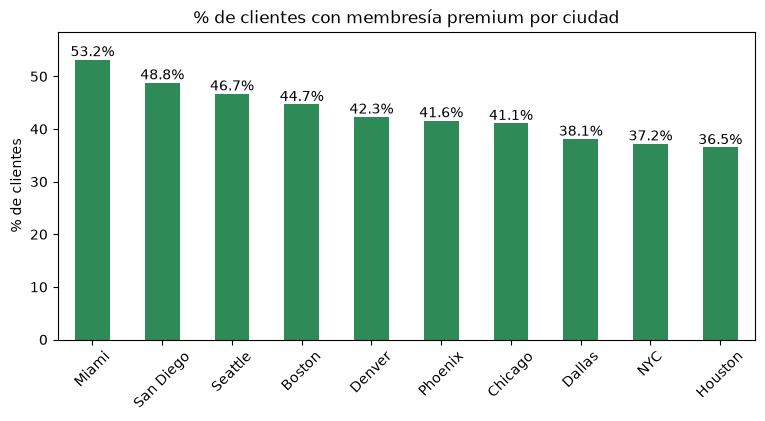

==== % de clientes de cada estrato por ciudad ====


estrato_socioeconomico,Bajo,Medio,Alto,Muy Alto,Alto + Muy Alto
ciudad_residencia,,,,,
Miami,14.0,24.6,36.4,25.1,61.5
San Diego,15.1,26.7,35.5,22.7,58.2
Seattle,18.5,28.0,33.1,20.4,53.5
Boston,20.7,28.6,29.8,20.9,50.7
Denver,20.0,30.3,33.6,16.1,49.7
Phoenix,22.6,31.9,28.7,16.8,45.5
Chicago,21.3,33.4,28.1,17.2,45.3
Dallas,24.0,33.2,28.3,14.5,42.8
NYC,23.8,36.0,25.5,14.8,40.3


consume_licor,No,Sí
rango_edad,,
18-29,9.7,90.3
30-44,47.4,52.6
45-59,43.8,56.2
60-80,44.3,55.7


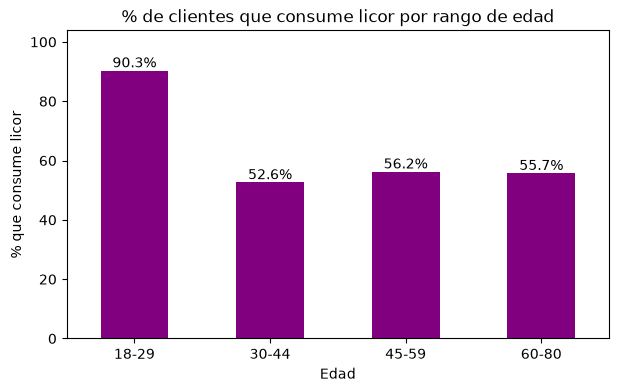

==== Chicago: clientes por preferencia vs oferta de restaurantes en Yelp ====


,clientes,pct_clientes,gasto_promedio_usd,calificacion_promedio,nivel_precio_promedio
preferencias_alimenticias,,,,,
Carnes,1589,29.5,26.3,4.0,2.9
Vegetariano,1123,20.9,27.7,4.3,2.2
Mariscos,696,12.9,27.7,4.2,2.6
Vegano,571,10.6,26.4,4.3,2.1
Pescado,546,10.1,26.3,4.1,2.2


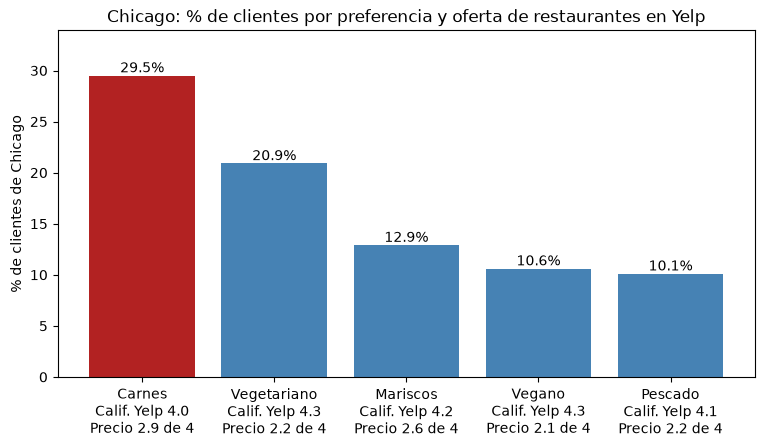

In [6]:
# ============================================================
# BLOQUE 6 (AVANCE 3): PREFERENCIAS, PERFIL, MEMBRESÍAS Y ALCOHOL
# ============================================================

# --- Gráfico 1: preferencias alimenticias en todas las ciudades ---

# Tabla: % de cada preferencia dentro de cada ciudad (cada fila suma 100%)
pref_ciudad = (pd.crosstab(df_total["ciudad_residencia"], df_total["preferencias_alimenticias"],
                           normalize="index") * 100).round(1)
display(pref_ciudad)

# Barras apiladas: cada barra es una ciudad dividida por preferencias
pref_ciudad.plot(kind="barh", stacked=True, figsize=(10, 5), colormap="tab20")
plt.title("Preferencias alimenticias por ciudad (%)")
plt.xlabel("% de clientes")
plt.ylabel("")
plt.legend(title="Preferencia", bbox_to_anchor=(1, 1))   # pone la leyenda afuera para no tapar barras
plt.show()


# --- Perfil de los clientes de mayor gasto ---

# Definimos "mayor gasto" como el 10% de clientes que más gasta al mes
limite_top = df_total["gasto_mensual"].quantile(0.9)    # el valor que separa al 10% superior
print("Gasto mensual mínimo para estar en el top 10%:", round(limite_top, 1), "USD")

# Marcamos a cada cliente como "Top 10%" o "Resto"; los que no tienen gasto quedan vacíos
df_total["grupo_gasto"] = np.where(df_total["gasto_mensual"] >= limite_top, "Top 10%", "Resto")
df_total.loc[df_total["gasto_mensual"].isna(), "grupo_gasto"] = np.nan

# ¿Cuánto suelen gastar al mes? Comparamos los dos grupos
print("==== Gasto mensual: top 10% vs resto ====")
display(df_total.groupby("grupo_gasto")["gasto_mensual"].agg(["count", "mean", "median"]).round(1))

# ¿Qué comidas les gustan? % de cada preferencia dentro de cada grupo
pref_top = (pd.crosstab(df_total["preferencias_alimenticias"], df_total["grupo_gasto"],
                        normalize="columns") * 100).round(1)
display(pref_top.sort_values("Top 10%", ascending=False))

pref_top.sort_values("Top 10%").plot(kind="barh", figsize=(8, 5))
plt.title("Preferencias alimenticias: top 10% de gasto vs resto (%)")
plt.xlabel("% de clientes del grupo")
plt.ylabel("")
plt.show()

# ¿De qué estrato son? % de cada estrato dentro de cada grupo
print("==== Estrato: top 10% vs resto ====")
display((pd.crosstab(df_total["estrato_socioeconomico"], df_total["grupo_gasto"],
                     normalize="columns") * 100).round(1).reindex(orden_estrato))


# --- ¿En qué ciudad pagan más membresías? ---

# Contamos las membresías premium por ciudad
membresias = df_total[df_total["membresia_premium"] == "Sí"]["ciudad_residencia"].value_counts().to_frame("membresias")
# Calculamos qué % de los clientes de cada ciudad tiene membresía
# POR QUÉ: las ciudades tienen distinto tamaño, así que el conteo solo no basta para comparar
membresias["pct_de_la_ciudad"] = (membresias["membresias"] / df_total["ciudad_residencia"].value_counts() * 100).round(1)

# Ordenamos por porcentaje, que es lo que permite comparar ciudades de distinto tamaño
membresias = membresias.sort_values("pct_de_la_ciudad", ascending=False)
display(membresias)

# Graficamos el % (no la cantidad), porque es el dato con el que comparamos ciudades
ax = membresias["pct_de_la_ciudad"].plot(kind="bar", color="seagreen", figsize=(9, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")   # escribe el % encima de cada barra
ax.margins(y=0.1)
plt.title("% de clientes con membresía premium por ciudad")
plt.xlabel("")
plt.ylabel("% de clientes")
plt.xticks(rotation=45)
plt.show()


# ¿Por qué Miami tiene más membresías? Vemos qué % de los clientes de cada ciudad es de cada estrato
# POR QUÉ: la membresía depende del estrato, así que una ciudad con más clientes Alto y Muy Alto tendrá más membresías
estrato_ciudad = (pd.crosstab(df_total["ciudad_residencia"], df_total["estrato_socioeconomico"],
                              normalize="index") * 100).round(1)[orden_estrato]
estrato_ciudad["Alto + Muy Alto"] = estrato_ciudad["Alto"] + estrato_ciudad["Muy Alto"]
print("==== % de clientes de cada estrato por ciudad ====")
display(estrato_ciudad.sort_values("Alto + Muy Alto", ascending=False))

# --- Relación entre consumo de alcohol y edad ---

# Agrupamos las edades en rangos para comparar mejor
df_total["rango_edad"] = pd.cut(df_total["edad"], bins=[18, 30, 45, 60, 81],
                                labels=["18-29", "30-44", "45-59", "60-80"], right=False)

# % que consume licor dentro de cada rango de edad (cada fila suma 100%)
licor_edad = (pd.crosstab(df_total["rango_edad"], df_total["consume_licor"], normalize="index") * 100).round(1)
display(licor_edad)

ax = licor_edad["Sí"].plot(kind="bar", color="purple", figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.margins(y=0.15)
plt.title("% de clientes que consume licor por rango de edad")
plt.xlabel("Edad")
plt.ylabel("% que consume licor")
plt.xticks(rotation=0)
plt.show()


# --- Preferencias en Chicago vs oferta en Yelp (datos integrados en el Avance 2) ---

import os   # os sirve para revisar si un archivo existe en la carpeta

archivo_yelp = "integrado_clientes_yelp_chicago.csv"

# POR QUÉ: este archivo lo genera Avance_API_Yelp.ipynb (Bloque 3). Si todavía no se ha corrido,
# avisamos en vez de dar error, así el notebook corre completo en cualquier orden
if os.path.exists(archivo_yelp):
    # "Otro" y "No especificado" se quitan porque no se buscaron en Yelp (no son un tipo de comida concreto)
    yelp_pref = (pd.read_csv(archivo_yelp)
                 .dropna(subset=["calificacion_promedio"])
                 .set_index("preferencias_alimenticias"))
    print("==== Chicago: clientes por preferencia vs oferta de restaurantes en Yelp ====")
    display(yelp_pref[["clientes", "pct_clientes", "gasto_promedio_usd",
                       "calificacion_promedio", "nivel_precio_promedio"]])

    # Resaltamos Carnes: es la más pedida y, a la vez, la peor calificada y la más cara en Yelp
    colores = ["firebrick" if p == "Carnes" else "steelblue" for p in yelp_pref.index]

    # Debajo de cada barra escribimos la calificación y el precio promedio de Yelp
    etiquetas = [p + "\nCalif. Yelp " + str(c) + "\nPrecio " + str(n) + " de 4"
                 for p, c, n in zip(yelp_pref.index, yelp_pref["calificacion_promedio"],
                                    yelp_pref["nivel_precio_promedio"])]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar_label(ax.bar(etiquetas, yelp_pref["pct_clientes"], color=colores), fmt="%.1f%%")
    ax.margins(y=0.15)
    plt.title("Chicago: % de clientes por preferencia y oferta de restaurantes en Yelp")
    plt.ylabel("% de clientes de Chicago")
    plt.show()
else:
    print("Falta el archivo", archivo_yelp)
    print("Primero corre Avance_API_Yelp.ipynb y luego vuelve a correr este notebook.")


## Hallazgos – Avance 3 (todas las ciudades)
- **Gasto mensual:** se calculó como visitas al mes × gasto por comida (supuesto: la frecuencia es mensual). Se pudo calcular para 28.318 de 30.000 clientes.
- **Clientes por ciudad:** Chicago (5.384) y NYC (4.769) concentran el 34% de la base; Phoenix es la más pequeña (1.511).
- **Estratos:** Medio (31,1%) y Alto (30,1%) son los más comunes; Muy Alto es el 18,3%.
- **Gasto por ciudad:** Miami es donde más se gasta al mes (~226 USD); Houston (~129) y Chicago (~140) son donde menos. Comparando estrato con estrato, NYC es la que más gasta en Medio, Alto y Muy Alto (Muy Alto: ~601 USD vs ~410 en Chicago); en Bajo lidera Miami.
- **Frecuencia vs gasto por comida:** el estrato define las dos cosas. Entre quienes sí comen afuera, Bajo visita ~2 veces y gasta ~12 USD por comida; Muy Alto visita ~7,5 veces y gasta ~64. Dentro de cada estrato, visitar más no cambia lo que se gasta por comida. Además, el 23,7% del estrato Bajo nunca visita restaurantes.
- **Ingresos vs gasto mensual:** la correlación general es 0,71, pero dentro de cada estrato es ~0. Cada estrato es un tramo de ingresos (Bajo 800–1.599, Medio 1.600–3.499, Alto 3.500–8.999, Muy Alto 9.002–17.999 USD), así que la relación existe solo entre estratos.
- **Preferencias por ciudad:** Carnes lidera en 6 de 10 ciudades (en Denver casi empata con Vegetariano). Vegetariano lidera en Boston (27,8%), Seattle y San Diego; Mariscos en Miami (25,7%).
- **Clientes de mayor gasto (top 10%):** gastan desde ~423 USD al mes (mediana ~642). El 95,8% es de estrato Muy Alto. Sus preferencias alimenticias son casi iguales a las del resto: lo que los distingue es el estrato, no la comida.
- **Membresías:** Chicago tiene más membresías en cantidad (2.215), pero Miami tiene el mayor porcentaje (53,2%). La membresía depende casi totalmente del estrato (95% en Muy Alto vs menos de 1% en Bajo), y Miami es la ciudad con más clientes Alto y Muy Alto (61,5%; Alto 36,4%).
- **Alcohol y edad:** el 90,3% de los clientes de 18–29 años consume licor, frente a ~53–56% en los demás rangos.
- **Chicago vs Yelp:** Carnes es la preferencia más pedida (29,5%), pero en Yelp sus restaurantes tienen la peor calificación (4,0) y el precio más alto (2,9 de 4). Vegetariano y Vegano están mejor calificados (4,3) y son más baratos (2,2 y 2,1 de 4). Oportunidad: carnes de precio medio y buena calidad.

==== Perfil de cada segmento (todas las ciudades) ====


,clientes,visitas_al_mes,gasto_por_comida,gasto_mensual,pct_clientes,pct_del_gasto
segmento,,,,,,
Premium,5476,7.5,64.4,481.0,18.3,50.2
Alto valor,9038,5.0,38.1,191.4,30.1,32.8
En crecimiento,9325,3.5,24.2,84.9,31.1,15.0
Ocasional,4698,2.0,11.7,23.3,15.7,2.1
Por activar,1463,0.0,0.0,0.0,4.9,0.0


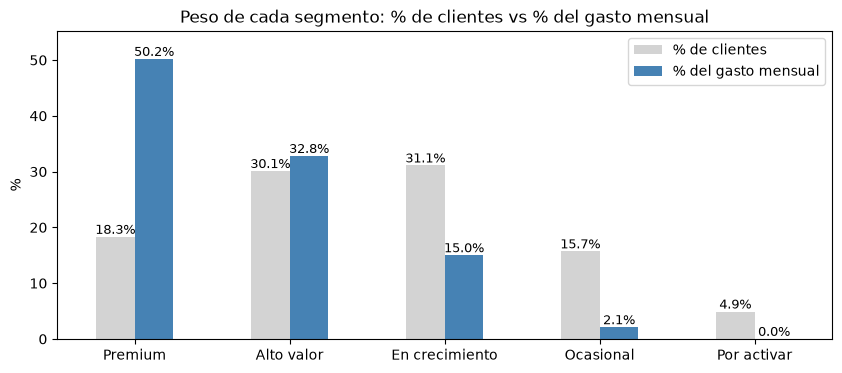

==== Gasto mensual promedio con y sin membresía, dentro de cada estrato (USD) ====


membresia_premium,No,Sí
estrato_socioeconomico,,
Bajo,17.5,16.3
Medio,84.7,86.2
Alto,190.8,191.6
Muy Alto,466.2,481.7


In [7]:
# ============================================================
# BLOQUE 7 (AVANCE 3): SEGMENTACIÓN DE CLIENTES
# ============================================================

# --- Paso 1: Crear los segmentos ---

# CRITERIO: en los Bloques 5 y 6 vimos que el estrato define el gasto
# (visitas, gasto por comida, membresía y top 10% dependen del estrato).
# Por eso segmentamos por estrato, y al estrato Bajo lo partimos en dos:
# los que sí visitan restaurantes y los que nunca visitan (0 visitas).
condiciones = [
    df_total["estrato_socioeconomico"] == "Muy Alto",
    df_total["estrato_socioeconomico"] == "Alto",
    df_total["estrato_socioeconomico"] == "Medio",
    (df_total["estrato_socioeconomico"] == "Bajo") & (df_total["frecuencia_visita"] == 0),
]
nombres = ["Premium", "Alto valor", "En crecimiento", "Por activar"]

# np.select le pone a cada cliente el nombre de la primera condición que cumple
# Si no cumple ninguna (Bajo que sí visita) queda como "Ocasional"
df_total["segmento"] = np.select(condiciones, nombres, default="Ocasional")

# Orden de los segmentos para la tabla y el gráfico (de mayor a menor gasto)
orden_segmentos = ["Premium", "Alto valor", "En crecimiento", "Ocasional", "Por activar"]


# --- Paso 2: Perfil de cada segmento ---

# Por cada segmento: cuántos clientes, visitas, gasto por comida y gasto mensual
perfil = df_total.groupby("segmento").agg(
    clientes=("id_persona", "count"),
    visitas_al_mes=("frecuencia_visita", "mean"),
    gasto_por_comida=("promedio_gasto_comida", "mean"),
    gasto_mensual=("gasto_mensual", "mean"),
    gasto_total=("gasto_mensual", "sum"))

# % de los clientes y % del gasto total de cada segmento
# POR QUÉ: así vemos qué segmentos pesan más en el gasto que en cantidad de clientes
perfil["pct_clientes"] = perfil["clientes"] / len(df_total) * 100
perfil["pct_del_gasto"] = perfil["gasto_total"] / df_total["gasto_mensual"].sum() * 100

# Ordenamos, quitamos el gasto total (ya quedó resumido en el %) y redondeamos
perfil = perfil.reindex(orden_segmentos).drop(columns="gasto_total").round(1)
print("==== Perfil de cada segmento (todas las ciudades) ====")
display(perfil)


# --- Paso 3: Gráfico: % de clientes vs % del gasto ---

ax = perfil[["pct_clientes", "pct_del_gasto"]].plot(kind="bar", rot=0, figsize=(10, 4),
                                                    color=["lightgray", "steelblue"])
for barras in ax.containers:                         # un grupo de barras por columna
    ax.bar_label(barras, fmt="%.1f%%", fontsize=9)   # escribe el % encima de cada barra
ax.margins(y=0.1)
plt.title("Peso de cada segmento: % de clientes vs % del gasto mensual")
plt.xlabel("")
plt.ylabel("%")
plt.legend(["% de clientes", "% del gasto mensual"])
plt.show()


# --- Paso 4: ¿La membresía hace que el cliente gaste más? ---

# Comparamos el gasto CON y SIN membresía dentro del mismo estrato
# POR QUÉ: sin separar por estrato, la membresía parece subir el gasto
# solo porque casi todos los de estrato Muy Alto la tienen
membresia_gasto = df_total.pivot_table(index="estrato_socioeconomico", columns="membresia_premium",
                                       values="gasto_mensual", aggfunc="mean").reindex(orden_estrato).round(1)
print("==== Gasto mensual promedio con y sin membresía, dentro de cada estrato (USD) ====")
display(membresia_gasto)

## Segmentación y recomendaciones

**Criterio:** el estrato define casi todo el gasto (Bloques 5 y 6), así que los segmentos se basan en el estrato. El estrato Bajo se divide entre quienes sí visitan y quienes nunca visitan.

| Segmento | Quiénes son | % clientes | % del gasto | USD al mes |
|---|---|---|---|---|
| Premium | Estrato Muy Alto | 18,3% | 50,2% | ~481 |
| Alto valor | Estrato Alto | 30,1% | 32,8% | ~191 |
| En crecimiento | Estrato Medio | 31,1% | 15,0% | ~85 |
| Ocasional | Bajo que sí visita | 15,7% | 2,1% | ~23 |
| Por activar | Bajo con 0 visitas | 4,9% | 0% | 0 |

**Recomendaciones:**
- **Premium (prioridad alta): retener.** Es el 18% de los clientes y aporta la mitad del gasto. Fidelizar con experiencia (reservas prioritarias, eventos), no con descuentos. Probar una oferta de mayor precio en NYC y Phoenix, donde el estrato Muy Alto gasta más (~601 y ~569 USD al mes, Bloque 5).
- **Alto valor (prioridad alta): subir el gasto por visita.** Ya visitan 5 veces al mes, pero gastan 38 USD por comida contra 64 del Premium. Usar maridajes, menús de mayor valor y venta sugerida.
- **En crecimiento (prioridad media): más visitas.** Es el segmento más grande (31%), pero visita solo 3,5 veces al mes. Usar programa de puntos y promociones entre semana.
- **Ocasional y Por activar (prioridad baja):** opciones económicas y, como mucho, un cupón de primera visita. No invertir mucho.
- **Jóvenes de 18 a 29:** el 90% consume licor (Bloque 6). Happy hour y carta de cócteles, con una versión de mayor precio para Premium y Alto valor.
- **Menú por ciudad:** Mariscos en Miami y Vegetariano en Boston, Seattle y San Diego (Bloque 6).
- **Miami como ciudad piloto para Alto valor:** mayor gasto mensual (~226 USD), más membresías (53,2%) y la mayor proporción de clientes de estrato Alto (36,4%) (Bloques 5 y 6).
- **Chicago – carnes:** la preferencia más pedida es también la peor calificada y la más cara en Yelp. Probar un concepto de carnes de precio medio (Bloque 6).

**Lo que la data no permite afirmar:** dentro del mismo estrato, los clientes con y sin membresía gastan casi lo mismo (Alto: 191 vs 192 USD), así que no se puede decir que la membresía aumente el gasto. La preferencia alimenticia tampoco distingue a los clientes de mayor gasto (Bloque 6). La base no tiene fechas, por eso no se puede medir retención.

El detalle está en `Documentacion/Recomendaciones.pdf`.